> **Antecedente de la versión 1.** El alcance vigente desde el 24/11/2026 es manzana roja, banano y limón. Este cuaderno conserva la preparación anterior con naranjas para trazabilidad. Continuar en el cuaderno 04 y consultar `config/alcance_actual.json`.

# Base revisada y arranque de SVM y Random Forest

**Proyecto estado de frutas · Algoritmos y Programación III**

Este cuaderno utiliza las etiquetas y máscaras revisadas visualmente por el asistente,
con atribución explícita en las anotaciones. El equipo puede corregirlas. No se ha
medido acuerdo entre revisores y las máscaras son contornos aproximados, no referencias
independientes de segmentación.

Comprobamos que la base es utilizable para ajustar los dos modelos tradicionales.
El lote contiene vistas relacionadas y pocas campañas por calidad. Por ello distinguimos
el ajuste inicial de un modelo de una evaluación independiente de su desempeño.

## 1. Leer y validar la base preparada

Ejecutar primero el cuaderno 02 si se cambiaron anotaciones. La exportación comprueba
las etiquetas vigentes, la revisión de cada máscara y las huellas de originales,
máscaras y entradas CNN. No se utilizan propuestas pendientes ni máscaras rechazadas.

In [1]:
from pathlib import Path
import sys
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import display
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
import sklearn

candidatas=[Path.cwd(),*Path.cwd().parents,Path.cwd()/'proyecto_estado_frutas']
PROYECTO=next(p for p in candidatas if (p/'estructura_proyecto.md').is_file())
if str(PROYECTO) not in sys.path:
    sys.path.insert(0,str(PROYECTO))
from src.data.exportar_base_modelado import exportar_base_modelado
from src.data.preparacion_imagenes import guardar_tabla,guardar_bytes_si_cambio

base,resumen,estado=exportar_base_modelado(PROYECTO)
SEMILLA=42
SALIDAS=PROYECTO/'experiments/results/arranque_modelos'
SALIDAS.mkdir(parents=True,exist_ok=True)
print('scikit-learn:',sklearn.__version__)
print('Ejemplares:',len(base),'| Fotografías:',estado['fotografias'],
      '| Grupos conservadores:',estado['grupos_conservadores'])
display(resumen)

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\juanp\\Documents\\Algoritmos&ProgramacionIII\\proyecto_estado_frutas\\experiments\\results\\preparacion_imagenes\\base_preparada.csv'

## 2. Evidencia de la revisión

Se inspeccionaron 194 fotografías y se probaron 102 regiones. La base conserva las
regiones que pasaron la revisión del original, la superposición y el recorte.
Las fotos con varias frutas se mantienen fuera como originales; sus ejemplares
aislados reciben etiquetas propias y conservan la relación con la foto de origen.

Se detectaron bananos dentro de `Apple_Good`, manzanas fuera del alcance rojo y
máscaras que seleccionaban manos, fondos o varios ejemplares. Las decisiones y
los rechazos están documentados en `data/annotations/revision_asistente_v1.json`.

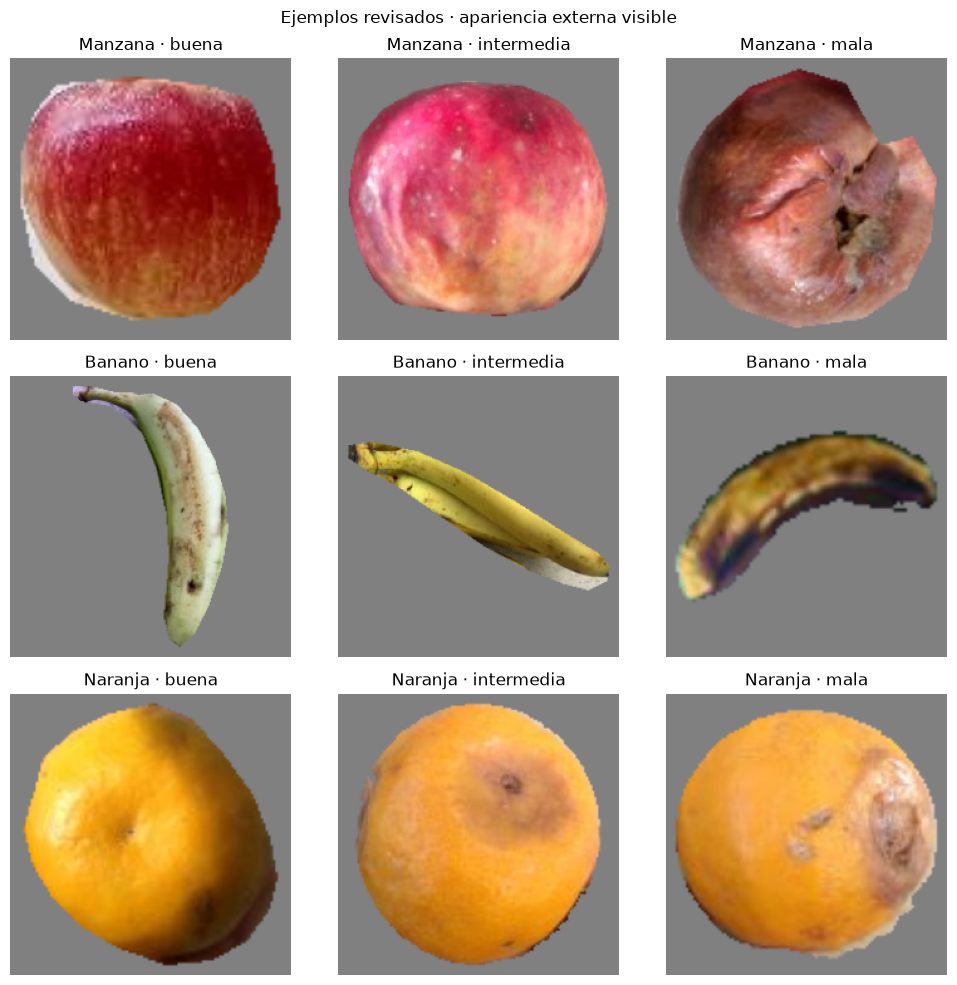

In [ ]:
preparada=pd.read_csv(PROYECTO/'experiments/results/preparacion_imagenes/base_preparada.csv')
ejemplos=preparada.sort_values('id_ejemplar').groupby(['fruta','calidad_revisada']).head(1)
fig,ejes=plt.subplots(3,3,figsize=(10,10))
frutas=['manzana','banano','naranja'];calidades=['buena','intermedia','mala']
for i,fruta in enumerate(frutas):
    for j,calidad in enumerate(calidades):
        fila=ejemplos.loc[ejemplos.fruta.eq(fruta)&ejemplos.calidad_revisada.eq(calidad)]
        ejes[i,j].axis('off')
        if not fila.empty:
            ejes[i,j].imshow(Image.open(fila.iloc[0].ruta_cnn))
        ejes[i,j].set_title(f'{fruta.capitalize()} · {calidad}')
fig.suptitle('Ejemplos revisados · apariencia externa visible')
fig.tight_layout()
from src.data.preparacion_imagenes import guardar_figura
guardar_figura(fig,SALIDAS/'ejemplos_base_revisada.jpg',dpi=110)
plt.show()

## 3. Entradas X e y

X contiene únicamente las 43 características de color, textura y forma. No entran
en X nombres de archivos, identificadores, fechas, grupos, etiqueta original ni
etiqueta revisada. El tipo de fruta se conserva para analizar resultados, sin
añadirlo como entrada en esta primera referencia.

La etiqueta objetivo es `calidad_revisada`: buena, intermedia o mala. Las variables
de ocupación y diámetro equivalente se reservan para el estudio de tamaño relativo.

In [ ]:
columnas=estado['caracteristicas']
X=base[columnas].astype(float).copy()
y=base['calidad_revisada'].copy()
grupos=base['grupo_particion'].copy()
assert len(X)==len(y)==len(grupos)
assert np.isfinite(X.to_numpy()).all()
assert set(y)=={'buena','intermedia','mala'}
assert not set(['fruta','calidad_revisada','grupo_particion','id_ejemplar']) & set(X.columns)
print('X:',X.shape,'| y:',y.shape)
display(pd.crosstab(base.fruta,y).reindex(index=['manzana','banano','naranja'],
    columns=['buena','intermedia','mala'],fill_value=0))

X: (43, 43) | y: (43,)


calidad_revisada,buena,intermedia,mala
fruta,,,
manzana,5,3,4
banano,3,3,3
naranja,11,5,6


## 4. Qué evaluación admite actualmente el lote

Se agrupan campañas de captura de forma conservadora para evitar que vistas de
los mismos objetos se repartan entre conjuntos. Esto no identifica con certeza cada
fruto físico, y el número de fotografías no se interpreta como número de muestras
independientes. Los grupos explorados durante la preparación permanecen en desarrollo.

El plan 60/20/20 del cuaderno 02 se activa solamente cuando hay cobertura agrupada
suficiente. No se sustituye por una división aleatoria de fotos para conseguir una
métrica favorable. Es necesario ampliar el conjunto con otros ejemplares/capturas,
especialmente calidad intermedia, antes de evaluar generalización.

In [ ]:
print('Lista para ajuste inicial:',estado['lista_para_ajuste_inicial'])
print('Lista para evaluación independiente:',estado['lista_para_evaluacion_independiente'])
print(estado['motivo_evaluacion'])
display(resumen[['fruta','calidad_revisada','ejemplares','grupos_conservadores']])

Lista para ajuste inicial: True
Lista para evaluación independiente: False
Se requieren al menos cinco grupos por fruta y calidad para este plan. Es un mínimo operativo, no garantía de suficiencia estadística.


,fruta,calidad_revisada,ejemplares,grupos_conservadores
0,banano,buena,3,2
1,banano,intermedia,3,1
2,banano,mala,3,2
3,manzana,buena,5,3
4,manzana,intermedia,3,2
5,manzana,mala,4,2
6,naranja,buena,11,3
7,naranja,intermedia,5,4
8,naranja,mala,6,2


## 5. Ajuste de referencia de SVM y Random Forest

Esta celda verifica que la base permite ajustar ambos estimadores. **No es una
comparación de desempeño ni una selección de hiperparámetros.** Se usa todo el lote
de desarrollo y no se calcula accuracy de entrenamiento como si fuera evaluación.

SVM utiliza estandarización dentro de un Pipeline; Random Forest trabaja con las
características sin escalar. `class_weight='balanced'` compensa frecuencias de calidad,
pero no corrige la escasez de ejemplares independientes ni las diferencias entre frutas.
Los parámetros son una referencia inicial explícita, pendiente de validación agrupada.

In [ ]:
modelos={
    'SVM':Pipeline([
        ('escalar',StandardScaler()),
        ('modelo',SVC(C=1.0,kernel='rbf',gamma='scale',class_weight='balanced')),
    ]),
    'Random Forest':RandomForestClassifier(n_estimators=100,min_samples_leaf=2,
        class_weight='balanced',random_state=SEMILLA,n_jobs=1),
}
ajustes=[]
for nombre,modelo in modelos.items():
    inicio=time.perf_counter()
    modelo.fit(X,y)
    assert set(modelo.classes_)==set(y)
    ajustes.append({'modelo':nombre,'filas_de_desarrollo':len(X),
                    'caracteristicas':X.shape[1],'clases':len(modelo.classes_),
                    'ajuste_completado':True})
comprobacion=pd.DataFrame(ajustes)
display(comprobacion)
guardar_tabla(comprobacion,SALIDAS/'comprobacion_ajuste.csv')
guardar_bytes_si_cambio(SALIDAS/'estado_ajuste.json',json.dumps({
    'sha_base_svm_rf':estado['sha_base_svm_rf'],
    'alcance':'Ajuste técnico sobre desarrollo; sin métricas de generalización.',
    'modelos':list(modelos),'evaluacion_independiente_realizada':False,
},ensure_ascii=False,indent=2).encode('utf-8'))

,modelo,filas_de_desarrollo,caracteristicas,clases,ajuste_completado
0,SVM,43,43,3,True
1,Random Forest,43,43,3,True


## 6. Continuación

La base revisada queda en `data/processed/base_revisada_v1/base_svm_rf.csv`.
Las anotaciones y máscaras revisadas se conservan separadas de las salidas calculadas.
Si cambia una decisión, volver a ejecutar la exportación del cuaderno 02 y este cuaderno.

Para pasar a comparación rigurosa: añadir otros frutos y capturas, realizar una segunda
revisión de las etiquetas difíciles, identificar grupos y reservar una prueba que no se
use para diseñar el procesamiento. Después se ajustarán C/gamma y parámetros del bosque
mediante validación agrupada, con macro-F1, balanced accuracy, matriz de confusión y
análisis por fruta. El conjunto de prueba se usará solo al terminar la selección.